# Lab 00: How to set up the lab environment

**CPU | API key: `OPENAI_API_KEY` for Parts D and E**

## Goal

Set up the environment every later lab assumes, and prove that each piece works: the pinned packages, the data files,
the shop's Ops API and a call to the chat model. Watch the reply to that call: it names the model that answered, and
one line in `models.env` chose that model for every lab in this repository.

## What you will learn

- How every lab in this repository starts, on Colab or on your own machine, and what its first two cells do.
- How to check that the installed packages match their pins in `requirements.txt`.
- How to prove with SHA-256 hashes that the data files are unchanged, and how to open the Chinook database read-only.
- How to start the shop's Ops API in a notebook and call it over HTTP.
- How to call the chat model with the OpenAI SDK, read the reply's text and token usage, and make the same call
  through LangChain.
- How `models.env` chooses the model for every lab, and how to change it.

## The first two cells

Every lab in this repository opens with the same two cells.

**Setup** finds the repository folder. On Colab it first copies the repository into the session with a shallow `git
clone` (only the latest version of each file) and installs the packages in `requirements.txt`. On your own machine you
ran `uv sync` once, so the cell installs nothing.

**Config** reads the model names from `models.env` in the repository folder, the one file that sets them for every
lab. If you put the same name in your `.env` file or in an environment variable, your value wins. Then it looks for
your OpenAI key: in the environment, in `.env`, then in Colab Secrets. It prints where it found the key, never the
key.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


On Colab the install adds the missing packages and upgrades `openai` from the 2.x series to 3.24.0. pip then says
*"you may need to restart the kernel"*; in a fresh session you need not, because nothing has loaded the old `openai`
yet.

⚠️ If you ran other cells first, the old `openai` may already be loaded, and Part D then fails with `ImportError:
cannot import name ... from 'openai...'`. Use **Runtime → Restart session** and run the notebook from the top; the
clone is skipped the second time.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


`CHAT_MODEL` is the model every lab calls, `JUDGE_MODEL` grades answers in the evaluation lab, and `EMBED_MODEL` turns
text into numbers for search. `REASONING_EFFORT` stays empty for a model without that setting; the comment above it in
`models.env` lists the values a reasoning model accepts. No notebook names a model in its code. Part F shows the line
that sets `CHAT_MODEL`. The outputs saved in this notebook come from `gpt-4o-mini-2024-07-18` on 12 Oct 2026.

If the key line says `not found`, Parts A to C still run. Add the key before Part D (see the troubleshooting table at
the end).

The map below shows which file or service each part of this lab touches.

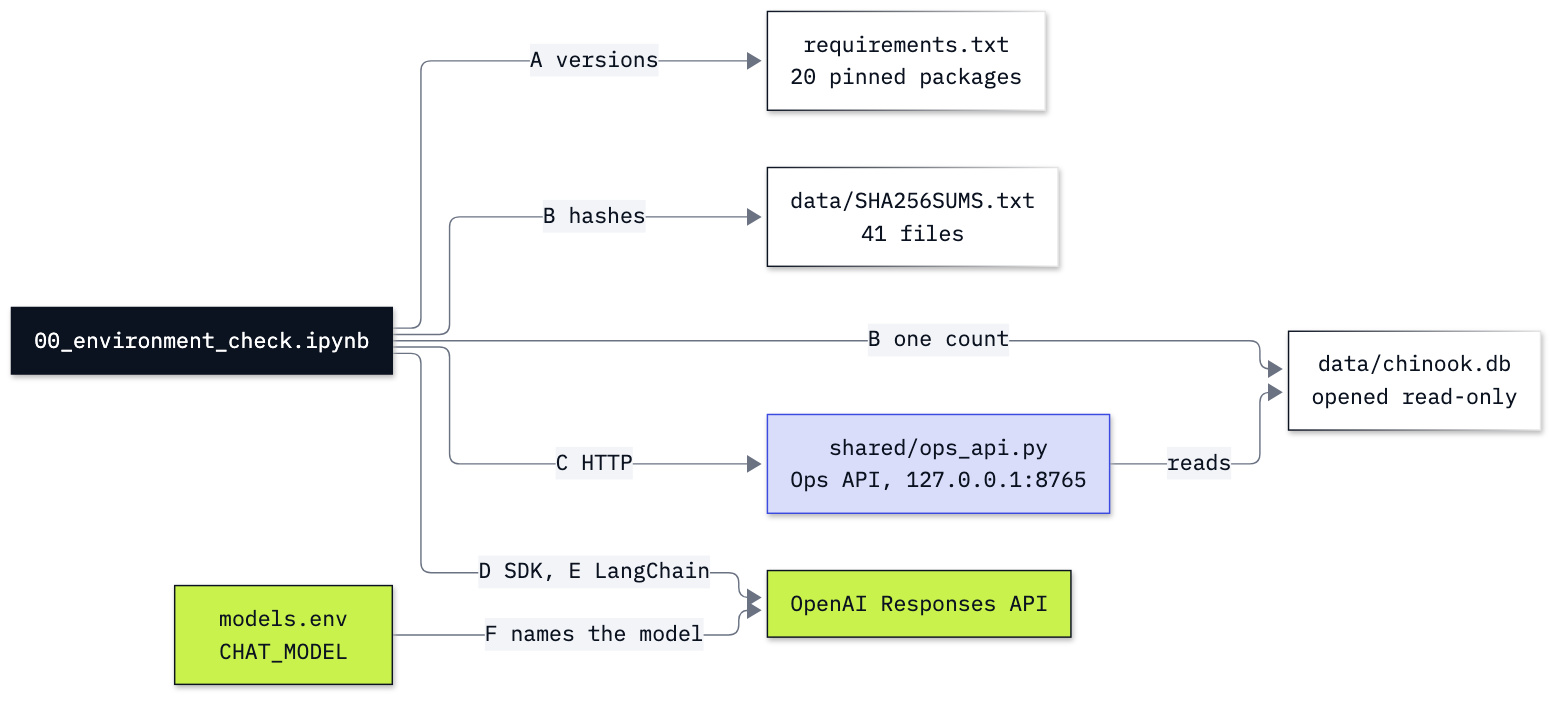

In [3]:
from IPython.display import Image
Image(filename=ROOT / "00_Environment_Check" / "resources" / "lab00_checks.png", width=760)

---

## Part A: Check the installed packages

This part proves your packages are the versions every saved output in these labs came from.

The versions are pinned in `requirements.txt`. A different version is a different library: a later lab's output,
warning or error might not match what the notebook shows.

First, the Python version. Colab runs Python 3.13, and the local setup asks `uv` for 3.13 too, so a value that moves
between versions moves for everyone.

In [4]:
import platform

print("Python  ", platform.python_version())
print("Platform", "Colab" if IN_COLAB else platform.system())

Python   3.13.5
Platform Darwin


Next, the pins. `requirements.txt` holds one `name==version` line per package. We read it into a dictionary rather
than typing the list again, so this check always tests the file that installed the packages.

In [5]:
pins = {}
for line in (ROOT / "requirements.txt").read_text().splitlines():
    if line and not line.startswith("#"):
        name, pinned = line.split("==")
        pins[name] = pinned

print(len(pins), "pinned packages")
print(list(pins.items())[:3])

20 pinned packages
[('langchain', '1.4.3'), ('langchain-core', '1.6.6'), ('langchain-openai', '1.6.7')]


Now compare each pin with what is installed. `importlib.metadata.version` asks the environment the notebook runs in,
which is the one that matters: a terminal can show a different Python from the notebook's kernel.

In [6]:
from importlib.metadata import version, PackageNotFoundError

mismatches = 0
for name, pinned in pins.items():
    try:
        installed = version(name)
    except PackageNotFoundError:
        installed = "missing"
    if installed != pinned:
        mismatches += 1
    status = "ok" if installed == pinned else "DIFFERENT"
    print(f"{name:28}{installed:10} pin {pinned:10} {status}")

print("\nPackages that differ from their pin:", mismatches)

langchain                   1.4.3      pin 1.4.3      ok
langchain-core              1.6.6      pin 1.6.6      ok
langchain-openai            1.6.7      pin 1.6.7      ok
langchain-classic           1.0.8      pin 1.0.8      ok
langchain-text-splitters    1.1.3      pin 1.1.3      ok
langgraph                   1.2.12     pin 1.2.12     ok
langgraph-checkpoint        4.2.0      pin 4.2.0      ok
langgraph-checkpoint-sqlite 3.1.1      pin 3.1.1      ok
openai                      3.24.0     pin 3.24.0     ok
tiktoken                    0.14.0     pin 0.14.0     ok
faiss-cpu                   1.15.1     pin 1.15.1     ok
gradio                      6.29.0     pin 6.29.0     ok
huggingface-hub             1.33.0     pin 1.33.0     ok
fastapi                     0.141.1    pin 0.141.1    ok
uvicorn                     0.54.0     pin 0.54.0     ok
httpx                       0.28.1     pin 0.28.1     ok
pydantic                    2.13.5     pin 2.13.5     ok
python-dotenv               1.2

Every line should say `ok`; the troubleshooting table at the end covers `DIFFERENT` and `missing`. Do not upgrade a
pinned package yourself, even to silence a warning: later labs were run and written on these versions.

### Checkpoint A

| You should see | Our run |
|---|---|
| Python | 3.13.x |
| Packages that differ from their pin | 0 (20 packages) |

---

## Part B: Check the data files

This part proves the files every lab reads are the ones the saved outputs came from.

The labs read the shop's policies and tickets, the support handbook, the Chinook database, a prebuilt search index and
five evaluation cases from `data/`. Many checkpoints depend on the exact text, such as a search's scores over the
handbook. A SHA-256 hash is a 64-character fingerprint of a file's bytes. Change one byte and the fingerprint changes
completely, so matching hashes prove the files are unchanged.

First, what is in `data/`.

In [7]:
DATA = ROOT / "data"

for path in sorted(DATA.iterdir()):
    if path.is_dir():
        print(f"{path.name + '/':16}folder, {len(list(path.iterdir()))} item(s)")
    elif not path.name.startswith("."):
        print(f"{path.name:16}{path.stat().st_size:,} bytes")

README.md       4,520 bytes
SHA256SUMS.txt  3,991 bytes
chinook.db      884,736 bytes
corpus/         folder, 36 item(s)
evalset.json    4,645 bytes
handbook/       folder, 1 item(s)
index/          folder, 2 item(s)


Hash one file first: the support handbook. `hashlib.sha256` takes the file's bytes and `hexdigest()` writes the result
as 64 hexadecimal characters.

In [8]:
import hashlib

handbook = DATA / "handbook" / "support_handbook.md"
print(hashlib.sha256(handbook.read_bytes()).hexdigest())

d27874b858aecefed0116e5b520d614592c408863dc3085ddd73671e34effaea


`data/README.md` records the handbook as `d27874b8…effaea`. Compare the first and last few characters with the output
above.

Checking 41 files by eye would be slow. `data/SHA256SUMS.txt` lists the expected hash of every file, one per line, in
the format the `sha256sum` and `shasum` commands use: the hash, two spaces, the path.

In [9]:
sums = (DATA / "SHA256SUMS.txt").read_text().splitlines()
print(len(sums), "lines")
for line in sums[:3]:
    print(line)

41 lines
d6c11e2ccda2a36883af57f031f76fbd55e247f3be1710c4c8aaa72ec06a18cb  chinook.db
9c516e87bce207d0ad0beccc97c13d4b119ad4bcca37f342a9ff771365ddbda1  corpus/policy_accounts.md
a3b23d42220682d9c96fe316f8d0c1b82e22151996847c502b4e33fbf246d3bc  corpus/policy_cancellations.md


Now hash every listed file and count the matches.

In [10]:
matched, changed = 0, []
for line in sums:
    expected, name = line.split("  ")
    actual = hashlib.sha256((DATA / name).read_bytes()).hexdigest()
    if actual == expected:
        matched += 1
    else:
        changed.append(name)

print(f"{matched} of {len(sums)} files match")
print("Changed:", changed or "none")

41 of 41 files match
Changed: none


If a file ever fails this check, get it back from the repository (see the troubleshooting table). Opening a data file
in an editor and saving it can be enough to fail it; Going further shows why.

### Open the Chinook database

Chinook is a sample database of a fictional online music shop: customers, employees, invoices and the tracks on them.
In these labs it is the shop's back office. `chinook.db` passed the hash check, so open it and ask it one question.

`sqlite3` ships with Python. The `?mode=ro` part of the address opens the file read-only, so nothing in this notebook
can change it.

In [11]:
import sqlite3

db = sqlite3.connect(f"file:{DATA / 'chinook.db'}?mode=ro", uri=True)
row = db.execute("SELECT COUNT(*) FROM customers").fetchone()
print(row)

(59,)


`fetchone()` returns one row as a tuple, here with one value: 59 customers. Going further joins the tables to find the
two customers the later labs use.

### Checkpoint B

| You should see | Our run |
|---|---|
| Files that match | 41 of 41 (36 corpus files, the handbook, `chinook.db`, the two index files, `evalset.json`) |
| Handbook hash | `d27874b858aecefed0116e5b520d614592c408863dc3085ddd73671e34effaea` |
| `chinook.db` hash | `d6c11e2ccda2a36883af57f031f76fbd55e247f3be1710c4c8aaa72ec06a18cb` |
| Customers | `(59,)` |

---

## Part C: Start the Ops API

This part starts the service the copilot acts through in the later labs, and calls it once.

The Ops API is a small web service, written with FastAPI for these labs: find a customer, list their invoices, read
one invoice, file a refund request. You call it in the labs; you do not write it. Its code is in `shared/ops_api.py`,
and it opens `chinook.db` read-only, as you just did.

⚠️ The labs in which the copilot calls the shop's API need this part. If it fails, you can go on to Part D and come
back to it.

`start_ops_api()` runs the service inside this notebook, in a background thread, on `127.0.0.1` (your own machine or
your Colab session, not the internet) at port 8765.

In [12]:
from shared.ops_api import start_ops_api

server = start_ops_api(port=8765)

Ops API started at http://127.0.0.1:8765


The Ops API answers `GET /health` when it is up, as most web services do. We call it with `httpx`, the HTTP client the
copilot's tools use later.

In [13]:
import httpx

API = "http://127.0.0.1:8765"
response = httpx.get(f"{API}/health")
print(response.status_code, response.json())

200 {'status': 'ok'}


Status 200 means the request worked. Now a real question: find the customer called Helena.

In [14]:
response = httpx.get(f"{API}/customers", params={"name": "Helena"})
customers = response.json()
print(response.status_code)
print(customers)

200
[{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic', 'support_rep': 'Steve Johnson'}]


The API returns a list, because a name can match more than one customer, with four fields per customer. The copilot
calls this endpoint to find who a ticket is about.

This lab does not need the service any more, so stop it. Each lab that uses it starts it again in its own setup.

In [15]:
if server:
    server.should_exit = True

### Checkpoint C

| You should see | Our run |
|---|---|
| `/health` | `200 {'status': 'ok'}` |
| `/customers?name=Helena` | `200`, one record: customer_id 6, Helena Holý, Czech Republic, Steve Johnson |

---

## Part D: Call the model with the OpenAI SDK

This part proves your key reaches the chat model, with OpenAI's own Python library and nothing in between.

⚠️ This part and the next each send one short request with your key, a small fraction of a US cent in all. Without a
key the first cell stops with `OpenAIError: Missing credentials`: add the key (see the troubleshooting table), run the
config cell again, then this part.

`OpenAI()` creates a client, which finds your key in the environment, where the config cell put it.
`client.responses.create` sends one request to OpenAI's [Responses
API](https://developers.openai.com/api/docs/guides/text) with two arguments: `model`, the name read from `models.env`,
and `input`, the question. The question is one a rep might ask on their first day.

In [16]:
from openai import OpenAI

client = OpenAI()
question = "How long does a digital download link last?"
response = client.responses.create(model=settings["CHAT_MODEL"], input=question)
print(response.output_text)

The duration a digital download link remains active can vary based on several factors, including:

1. **Source**: Different platforms and services have their own policies regarding download links.
2. **Expiration Period**: Many services set a specific expiration time (e.g., 24 hours, 7 days) after which the link becomes inactive.
3. **Download Limits**: Some links may allow a limited number of downloads before they expire.
4. **Account Status**: If the purchase is tied to a user's account, access could remain as long as the account is active.

Always check the terms and conditions provided by the service or platform from which you purchased the digital download to get precise details.


`output_text` is the text of the reply. Ours listed what a link's life depends on (the platform, an expiry time such
as 24 hours or 7 days, a download limit) and told us to check the seller's terms. Chinook has its own rule for
download links, in `data/corpus/policy_digital_downloads.md`, and this call did not send it; Lab 01 compares the two.
Here it is enough that an answer came back.

Every response also reports its token usage. Tokens are the pieces of text a model reads and writes, and you pay per
token.

In [17]:
print("input tokens: ", response.usage.input_tokens)
print("output tokens:", response.usage.output_tokens)
print("answered by:  ", response.model)

input tokens:  16
output tokens: 141
answered by:   gpt-4o-mini-2024-07-18


Input tokens count what you sent, here the question; output tokens count the reply. Ours: 16 in and 141 out. The same
question costs the same input every time; the output moves with the wording (150 to 184 tokens in five more runs).
`response.model` names the model that answered; Part F comes back to it.

### Checkpoint D

| You should see | Our run |
|---|---|
| The reply | a few lines on how long download links last, in any wording |
| Token usage | 16 input tokens; about 140 to 190 output (ours: 141) |
| `response.model` | `gpt-4o-mini-2024-07-18` |

---

## Part E: Make the same call through LangChain

This part proves LangChain is installed and reaches the same model. Lab 01 explains what LangChain does for you; here
it only has to answer.

`init_chat_model` builds a chat model from a model name and a provider. `use_responses_api=True` sends the request
through the same Responses API as Part D. `invoke` sends the question and returns the reply as a message.

In [18]:
from langchain.chat_models import init_chat_model

model = init_chat_model(settings["CHAT_MODEL"], model_provider="openai", use_responses_api=True)
reply = model.invoke(question)
print(reply.text)

The duration of a digital download link can vary widely depending on the provider and the specific terms associated with the download. Here are some common scenarios:

1. **Permanent Links**: Some services offer permanent links that do not expire, allowing you to download the file whenever you want.

2. **Time-Limited Links**: Many digital downloads come with a time limit, such as 24 hours to 7 days after purchase.

3. **Download Limit**: Some links may also have a limit on the number of times you can download the file, regardless of how long the link remains active.

4. **Subscription Services**: If the download is part of a subscription, the link may only be active as long as your subscription is valid.

For the most accurate information, it's always best to check the terms and conditions of the specific service you're using.


Ours was another list of the same kind, this time with permanent links and subscriptions in it. LangChain reports the
same token counts as the SDK, under its own names.

In [19]:
print(reply.usage_metadata["input_tokens"], "input tokens,", reply.usage_metadata["output_tokens"], "output tokens")
print("answered by:", reply.response_metadata["model_name"])

16 input tokens, 173 output tokens
answered by: gpt-4o-mini-2024-07-18


### Checkpoint E

| You should see | Our run |
|---|---|
| The reply | another wording of the same kind of answer |
| Token usage | 16 input tokens, as in Part D; its own output count (ours: 173) |
| Answered by | `gpt-4o-mini-2024-07-18`, as in Part D |

---

## Part F: Find the line that chose the model

This part shows where the model in both calls came from, and how to change it for every lab.

Neither call names a model in its code: both read `settings["CHAT_MODEL"]`. Print the line in `models.env` that sets
it, the value the config cell loaded, and the model that answered each call. Predict: will all four names be the same?

In [20]:
for line in (ROOT / "models.env").read_text().splitlines():
    if line.startswith("CHAT_MODEL="):
        print("models.env:      ", line)
print("loaded setting:  ", settings["CHAT_MODEL"])
print("SDK answer:      ", response.model)
print("LangChain answer:", reply.response_metadata["model_name"])

models.env:       CHAT_MODEL=gpt-4o-mini
loaded setting:   gpt-4o-mini
SDK answer:       gpt-4o-mini-2024-07-18
LangChain answer: gpt-4o-mini-2024-07-18


The first two match, and both answers name `gpt-4o-mini-2024-07-18`: `gpt-4o-mini` is an alias, and OpenAI reports the
dated version behind it that answered. One line in `models.env` chose the model for both calls, and it chooses it for
every lab in this repository.

To use another model in every lab, change that one line. To try one on your own machine only, set `CHAT_MODEL` in your
`.env` file or as an environment variable, and the loaded setting above then differs from the line (challenge task 2).
Another model words its replies differently, so in every lab check the facts a checkpoint names, not the wording.

### Checkpoint F

| You should see | Our run |
|---|---|
| `models.env` | `CHAT_MODEL=gpt-4o-mini` |
| Loaded setting | the same name, unless your `.env` or an environment variable sets another |
| Both answers | `gpt-4o-mini-2024-07-18` |

---

## Your record

Later labs compare their numbers with runs on other machines, so keep a short record of this one: the date, where it
ran, the Python version, the model that answered, and the result of each check. Copy the output into your notes.

In [21]:
from datetime import date

checks = {
    "A  Python 3.13 and pinned packages": platform.python_version().startswith("3.13") and mismatches == 0,
    "B  data hashes and Chinook": not changed and row[0] == 59,
    "C  Ops API answers": customers[0]["customer_id"] == 6,
    "D  OpenAI SDK call": response.usage.output_tokens > 0,
    "E  LangChain call": reply.usage_metadata["output_tokens"] > 0,
}

print("Run on", date.today().isoformat(), "|", "Colab" if IN_COLAB else platform.system(),
      "| Python", platform.python_version(), "|", response.model)
for name, passed in checks.items():
    print("✅" if passed else "❌", name)

Run on 2026-10-12 | Darwin | Python 3.13.5 | gpt-4o-mini-2024-07-18
✅ A  Python 3.13 and pinned packages
✅ B  data hashes and Chinook
✅ C  Ops API answers
✅ D  OpenAI SDK call
✅ E  LangChain call


## What you can do now

- Open any lab in this repository on Colab or locally; its first two cells are the ones you ran here.
- Tell whether an environment matches the repository's pins.
- Prove with a SHA-256 hash that a data file is unchanged, and open the Chinook database read-only.
- Start the Ops API in a notebook and call it over HTTP.
- Call the chat model with `client.responses.create`, read `output_text` and `usage`, and make the same call with
  `init_chat_model`.
- Find the line in `models.env` that chooses the model, and change it for every lab or only on your machine.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| Part A shows a Python other than 3.13 (local) | the notebook runs on another kernel | choose the repository's `.venv` kernel; run `uv sync` in the repository folder first |
| A package shows `DIFFERENT` or `missing` | the setup cell did not run, or Colab still had an older version loaded | run the setup cell; on Colab use Runtime → Restart session, then run from the top |
| `ModuleNotFoundError: No module named 'shared'` | the setup cell was skipped, or the notebook was opened outside the repository | run the setup cell first; locally, open the notebook from inside the repository folder |
| `StopIteration` in the setup cell (local) | the notebook is not inside the repository folder | open it from the cloned repository, where `models.env` sits |
| A data hash does not match | a file was opened and saved by an editor | locally, `git checkout -- data/<file>`; on Colab, delete the folder and run the setup cell again |
| `Ops API did not start on port 8765` | another program, not the Ops API, uses the port | restart the kernel; if it still fails, use `start_ops_api(port=8766)` and that port in `API` |
| The config cell says the key is `not found`, or Part D stops with `OpenAIError: Missing credentials` | no key in the environment, `.env` or Colab Secrets | Colab: add `OPENAI_API_KEY` under Secrets (key icon) and switch on notebook access; locally: put it in `.env`. Then run the config cell again |
| `AuthenticationError` in Part D | the key is wrong or was revoked | paste the key again; ask the instructor if it is a class key |
| `NotFoundError`, status 404: *The model `...` does not exist or you do not have access to it.* | `CHAT_MODEL` is misspelt, or your account cannot use that model | check `models.env` and any `CHAT_MODEL` line in `.env` |
| `RateLimitError` | a shared class key reached its limit | wait a minute and run the cell again; tell the instructor if it repeats |

## Going further

Two extras for the curious. Nothing later depends on them.

### Add one line break to a copy and hash it

Text editors often add a line break at the end of a file when you save it. Predict: if we add one line break to a copy
of the handbook, will the copy still read the same, and will its hash still match? We change a copy in a temporary
folder, never the real file.

In [22]:
import tempfile

copy = Path(tempfile.mkdtemp()) / "support_handbook.md"
copy.write_bytes(handbook.read_bytes() + b"\n")

print("Same words:  ", handbook.read_text().split() == copy.read_text().split())
print("Original hash", hashlib.sha256(handbook.read_bytes()).hexdigest()[:16], "...")
print("Copy hash    ", hashlib.sha256(copy.read_bytes()).hexdigest()[:16], "...")

Same words:   True
Original hash d27874b858aecefe ...
Copy hash     812f46c1d9bf66a1 ...


The words are identical and the hash is completely different. Opening a data file and saving it can break a checkpoint
in a later lab, which is why the labs only read `data/`.

### Join the Chinook tables

Two customers come back in later labs: Helena Holý and Puja Srivastava. This query joins three tables to count each
one's invoices, add up what they spent and name their support rep, the employee who looks after them.

In [23]:
QUERY = """
SELECT c.CustomerId, c.FirstName || ' ' || c.LastName AS name,
       COUNT(i.InvoiceId) AS invoices, ROUND(SUM(i.Total), 2) AS total,
       e.FirstName || ' ' || e.LastName AS support_rep
FROM customers c
JOIN invoices i  ON i.CustomerId = c.CustomerId
JOIN employees e ON e.EmployeeId = c.SupportRepId
WHERE c.FirstName IN ('Helena', 'Puja')
GROUP BY c.CustomerId
"""
for customer in db.execute(QUERY):
    print(customer)

(6, 'Helena Holý', 7, 49.62, 'Steve Johnson')
(59, 'Puja Srivastava', 6, 36.64, 'Jane Peacock')


The connection is read-only. This update would move Helena to another country, and SQLite refuses it.

In [24]:
try:
    db.execute("UPDATE customers SET Country = 'Nowhere' WHERE CustomerId = 6")
except sqlite3.OperationalError as error:
    print("Refused:", error)

Refused: attempt to write a readonly database


The Ops API opens the database the same way, so the copilot cannot change a customer's record either. Its one write, a
refund request, goes to a separate file.

## Challenge

Use only what this lab showed. A worked solution is in `solved/` for the instructor.

1. **Puja through the Ops API.** Start the Ops API again, find Puja's customer number with `/customers?name=Puja`,
   then read her invoices at `/customers/<id>/invoices`. Expected: customer 59 in India, rep Jane Peacock, 6 invoices,
   36.64 in total, the same as the join in Going further.
2. **Change the model without editing a file.** Set `os.environ["CHAT_MODEL"]` to a name that does not exist, load the
   settings again with `load_settings()` and make Part D's call. Then delete the variable and load the settings once
   more. Expected: the settings show your name; the call fails with `NotFoundError`, status 404, before any tokens are
   used; after the delete, `CHAT_MODEL` is the name in `models.env` again.

## Resources

- [uv: working on projects](https://docs.astral.sh/uv/guides/projects/): `uv sync`, `.python-version` and the lock
  file
- [Python `hashlib`](https://docs.python.org/3/library/hashlib.html),
  [`sqlite3`](https://docs.python.org/3/library/sqlite3.html) and [SQLite URI
  filenames](https://www.sqlite.org/uri.html) (what `?mode=ro` does): Part B
- [Chinook Database](https://github.com/lerocha/chinook-database): the sample database's origin and licence
- [FastAPI tutorial](https://fastapi.tiangolo.com/tutorial/) and [HTTPX
  quickstart](https://www.python-httpx.org/quickstart/): the service and the client in Part C
- [OpenAI: text generation](https://developers.openai.com/api/docs/guides/text): `client.responses.create` and
  `output_text`, the call in Part D
- [LangChain: models](https://docs.langchain.com/oss/python/langchain/models): `init_chat_model`, the call in Part E
- [OpenAI: models](https://developers.openai.com/api/docs/models): the models you can name in `models.env`, with their
  prices and limits